In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/ecommerce_pricing.csv')

In [3]:
df.head()

,product_id,product_category,base_cost,competitor_price,inventory_level,demand_score,customer_rating,is_weekend,shipping_days,optimal_price
0,PROD_1001,Fashion,130.69,182.06,375,0.526,4.3,1,5,162.77
1,PROD_1002,Home & Kitchen,47.42,59.17,277,1.008,4.1,1,2,57.89
2,PROD_1003,Home & Kitchen,59.76,72.95,337,0.764,3.9,0,3,70.85
3,PROD_1004,Home & Kitchen,228.52,309.80,560,1.622,3.9,0,2,307.51
4,PROD_1005,Fitness,124.04,157.14,126,0.369,3.6,0,3,145.81


In [4]:
df.shape

(12000, 10)

In [8]:
df.isnull().sum()
df.isnull().sum() / len(df) * 100

product_id          0.0
product_category    0.0
base_cost           0.0
competitor_price    2.5
inventory_level     0.0
demand_score        0.0
customer_rating     2.5
is_weekend          0.0
shipping_days       0.0
optimal_price       0.0
dtype: float64

In [9]:
df_clean = df.drop(columns=['product_id'])

In [10]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
base_cost,12000.0,178.296490,139.621059,15.040,69.8600,141.730,248.8050,599.780
competitor_price,11700.0,223.604247,177.568467,5.970,86.7525,174.540,311.2875,903.480
inventory_level,12000.0,300.175750,173.294681,0.000,149.0000,301.000,450.0000,600.000
demand_score,12000.0,1.075220,0.414555,0.293,0.7990,1.005,1.2660,4.477
customer_rating,11700.0,4.062154,0.462734,2.800,3.7000,4.100,4.4000,5.000
is_weekend,12000.0,0.297750,0.457288,0.000,0.0000,0.000,1.0000,1.000
shipping_days,12000.0,3.167333,1.712477,1.000,2.0000,3.000,5.0000,7.000
optimal_price,12000.0,224.329104,176.738223,15.360,86.6775,177.345,312.7700,879.150


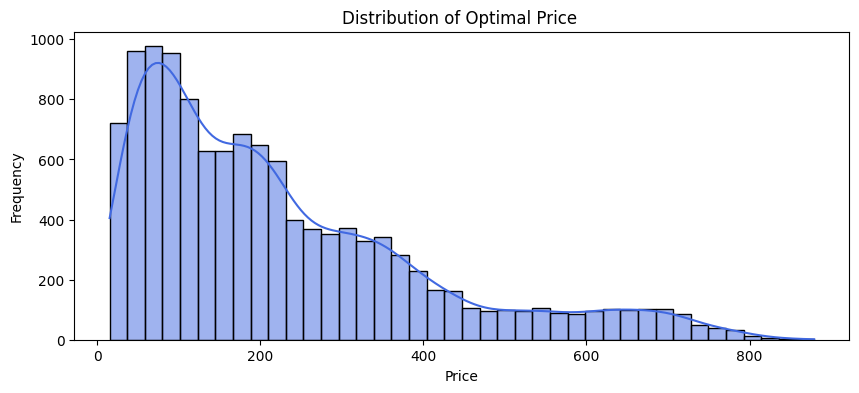

In [11]:
plt.figure(figsize=(10, 4))
sns.histplot(df_clean['optimal_price'], kde=True, bins=40, color='royalblue')
plt.title("Distribution of Optimal Price ")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

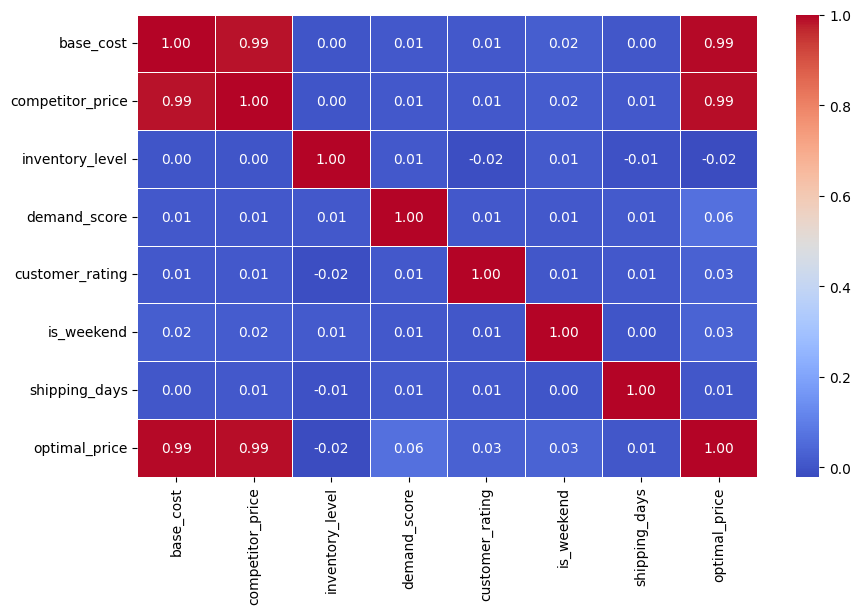

In [12]:
plt.figure(figsize=(10, 6))
correlation = df_clean.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.show()

In [13]:
df_clean['base_cost'].describe()

count    12000.000000
mean       178.296490
std        139.621059
min         15.040000
25%         69.860000
50%        141.730000
75%        248.805000
max        599.780000
Name: base_cost, dtype: float64

In [14]:
df['base_cost'].skew()

np.float64(1.1844021438781633)

In [22]:
df['base_cost'].corr(df['optimal_price'])

np.float64(0.9942916966606384)

<Axes: ylabel='Density'>

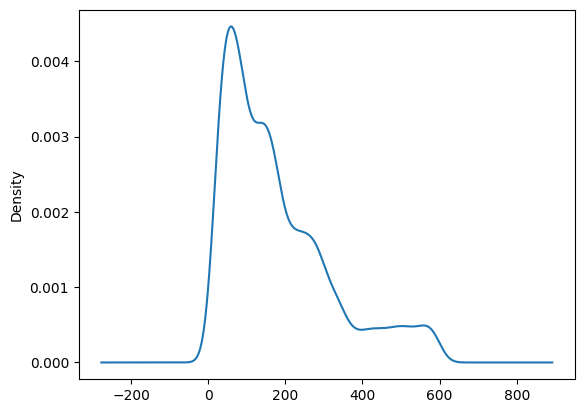

In [15]:
df['base_cost'].plot(kind='kde')

<Axes: xlabel='base_cost', ylabel='optimal_price'>

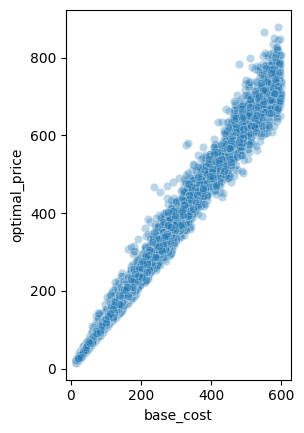

In [21]:
plt.subplot(1, 2, 2)
sns.scatterplot(x='base_cost', y='optimal_price', data=df_clean, alpha=0.3)

In [17]:
df_clean['competitor_price'].describe()

count    11700.000000
mean       223.604247
std        177.568467
min          5.970000
25%         86.752500
50%        174.540000
75%        311.287500
max        903.480000
Name: competitor_price, dtype: float64

In [18]:
df['competitor_price'].skew()

np.float64(1.2393470495014063)

In [23]:
df['competitor_price'].corr(df['optimal_price'])

np.float64(0.9911259667851497)

<Axes: ylabel='Density'>

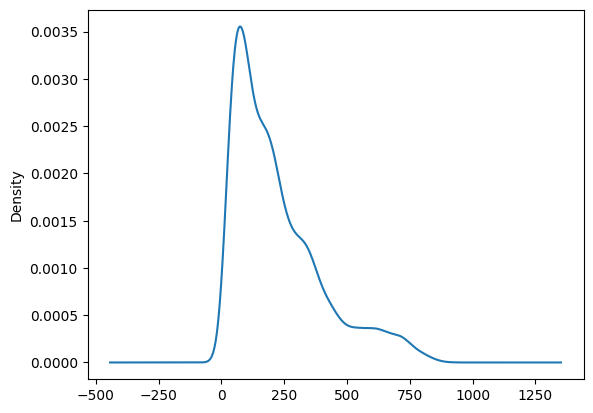

In [19]:
df['competitor_price'].plot(kind='kde')

<Axes: xlabel='competitor_price', ylabel='optimal_price'>

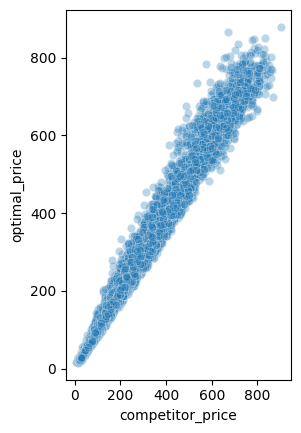

In [20]:
plt.subplot(1, 2, 2)
sns.scatterplot(x=df_clean['competitor_price'], y=df_clean['optimal_price'], alpha=0.3)

In [24]:
df_clean['inventory_level'].describe()

count    12000.000000
mean       300.175750
std        173.294681
min          0.000000
25%        149.000000
50%        301.000000
75%        450.000000
max        600.000000
Name: inventory_level, dtype: float64

In [25]:
df_clean['inventory_level'].skew()

np.float64(-0.010175347081511382)

In [26]:
df['inventory_level'].corr(df['optimal_price'])

np.float64(-0.02067327060890896)

Text(0, 0.5, 'Markup (Optimal Price / Base Cost)')

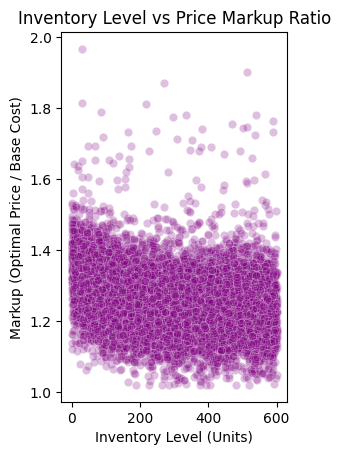

In [ ]:
plt.subplot(1, 2, 2)
markup = df_clean['optimal_price'] / df_clean['base_cost']
sns.scatterplot(x=df['inventory_level'], y=markup, alpha=0.25, color='purple')
plt.title("Inventory Level vs Price Markup Ratio")
plt.xlabel("Inventory Level")
plt.ylabel("Markup")

In [30]:
df_clean['demand_score'].describe()

count    12000.000000
mean         1.075220
std          0.414555
min          0.293000
25%          0.799000
50%          1.005000
75%          1.266000
max          4.477000
Name: demand_score, dtype: float64

In [33]:
df_clean['demand_score'].skew()

np.float64(2.086806207326922)

<Axes: ylabel='Density'>

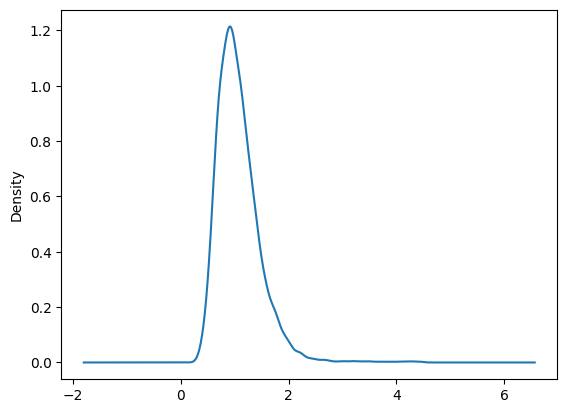

In [31]:
df['demand_score'].plot(kind='kde')

Text(0, 0.5, 'Markup')

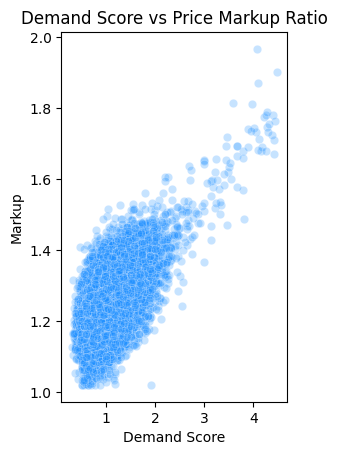

In [32]:
plt.subplot(1, 2, 2)
markup = df_clean['optimal_price'] / df_clean['base_cost']
sns.scatterplot(x=df['demand_score'], y=markup, alpha=0.25, color='dodgerblue')
plt.title("Demand Score vs Price Markup Ratio")
plt.xlabel("Demand Score")
plt.ylabel("Markup")

In [35]:
df_clean['customer_rating'].describe()

count    11700.000000
mean         4.062154
std          0.462734
min          2.800000
25%          3.700000
50%          4.100000
75%          4.400000
max          5.000000
Name: customer_rating, dtype: float64

In [36]:
df_clean['customer_rating'].skew()

np.float64(-0.40572863071221915)

<Axes: ylabel='Density'>

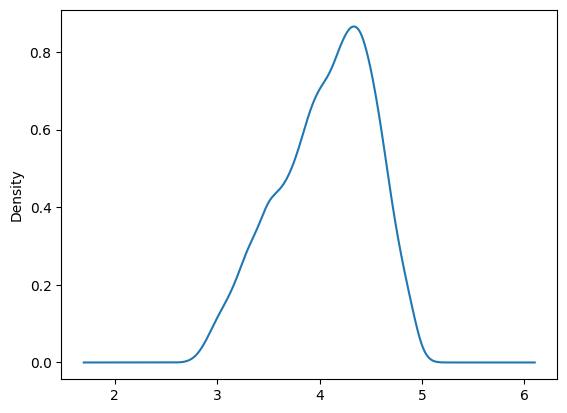

In [37]:
df_clean['customer_rating'].plot(kind='kde')

<Axes: xlabel='customer_rating', ylabel='None'>

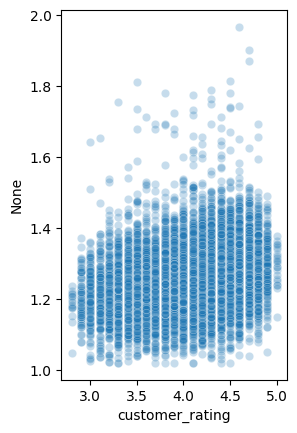

In [38]:
plt.subplot(1, 2, 2)
markup = df_clean['optimal_price'] / df_clean['base_cost']
sns.scatterplot(x=df_clean['customer_rating'], y=markup, alpha=0.25)

In [39]:
df_clean['shipping_days']

0        5
1        2
2        3
3        2
4        3
        ..
11995    5
11996    3
11997    2
11998    3
11999    5
Name: shipping_days, Length: 12000, dtype: int64

In [40]:
df_clean['shipping_days'].unique()

array([5, 2, 3, 1, 7])

<Axes: ylabel='Frequency'>

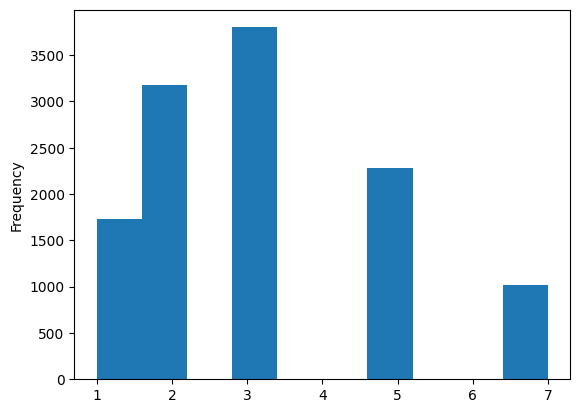

In [42]:
df_clean['shipping_days'].plot(kind='hist')

In [43]:
df_clean['is_weekend']

0        1
1        1
2        0
3        0
4        0
        ..
11995    0
11996    0
11997    0
11998    0
11999    1
Name: is_weekend, Length: 12000, dtype: int64

In [44]:
df_clean['is_weekend'].value_counts()

is_weekend
0    8427
1    3573
Name: count, dtype: int64

<Axes: ylabel='Frequency'>

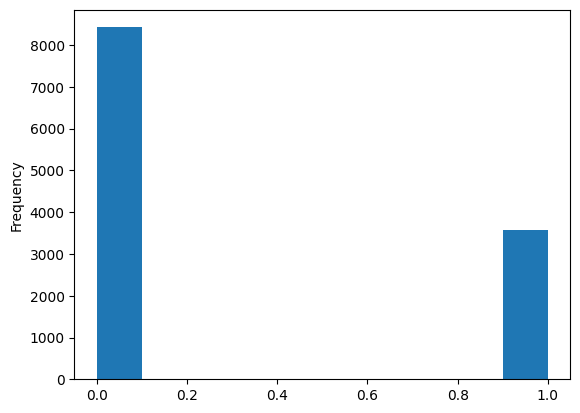

In [45]:
df_clean['is_weekend'].plot(kind='hist')

In [46]:
df_clean['product_category']

0               Fashion
1        Home & Kitchen
2        Home & Kitchen
3        Home & Kitchen
4               Fitness
              ...      
11995             Books
11996       Electronics
11997           Fashion
11998             Books
11999           Fashion
Name: product_category, Length: 12000, dtype: object

In [47]:
df_clean['product_category'].unique()

array(['Fashion', 'Home & Kitchen', 'Fitness', 'Electronics', 'Books'],
      dtype=object)

In [49]:
cat_summary = df_clean.groupby('product_category').agg(
    count=('optimal_price', 'count'),
    mean_base_cost=('base_cost', 'mean'),
    mean_optimal_price=('optimal_price', 'mean'),
    median_optimal_price=('optimal_price', 'median')
)
print("\nPricing Across Categories")
print(cat_summary)


Pricing Across Categories
                  count  mean_base_cost  mean_optimal_price  \
product_category                                              
Books              1802       53.105921           66.628685   
Electronics        2785      357.047142          449.484607   
Fashion            2821       97.373662          122.651900   
Fitness            1948      184.697048          232.077762   
Home & Kitchen     2644      156.960579          197.421044   

                  median_optimal_price  
product_category                        
Books                           66.170  
Electronics                    441.240  
Fashion                        123.150  
Fitness                        227.665  
Home & Kitchen                 194.555  


In [53]:
df_clean['product_category'].value_counts()

product_category
Fashion           2821
Electronics       2785
Home & Kitchen    2644
Fitness           1948
Books             1802
Name: count, dtype: int64

In [54]:
df_clean.head()

,product_category,base_cost,competitor_price,inventory_level,demand_score,customer_rating,is_weekend,shipping_days,optimal_price
0,Fashion,130.69,182.06,375,0.526,4.3,1,5,162.77
1,Home & Kitchen,47.42,59.17,277,1.008,4.1,1,2,57.89
2,Home & Kitchen,59.76,72.95,337,0.764,3.9,0,3,70.85
3,Home & Kitchen,228.52,309.80,560,1.622,3.9,0,2,307.51
4,Fitness,124.04,157.14,126,0.369,3.6,0,3,145.81


In [55]:
df_clean['optimal_price']

0        162.77
1         57.89
2         70.85
3        307.51
4        145.81
          ...  
11995     71.09
11996    210.85
11997    141.50
11998     56.34
11999    109.52
Name: optimal_price, Length: 12000, dtype: float64

In [56]:
df_clean['optimal_price'].skew()

np.float64(1.207875466847892)

In [57]:
df_clean['optimal_price'].min()

np.float64(15.36)

In [58]:
df_clean['optimal_price'].max()

np.float64(879.15)

In [59]:
df_clean['optimal_price'].mean()

np.float64(224.32910416666667)

In [60]:
df_clean['optimal_price'].median()

np.float64(177.34500000000003)

In [ ]:
drop_features = ['product_id']
categorical_features = ['product_category']
numerical_impute_features = ['competitor_price', 'customer_rating']
numerical_standard_features = ['base_cost', 'inventory_level', 'demand_score', 'shipping_days', 'is_weekend']
target_column = 'optimal_price'